# m03 - Feature-Group Ablation and Driver Importance

Which input groups does a GAEZ surrogate actually need? All numbers use the honest `pixel` CV (whole native GAEZ pixels
held out), 2 repeats, ten crops.

1. **Feature sets**: each group alone, cumulative additions, and leave-one-group-out from the full set.
2. **Leave-one-feature-out**: retrain without a single variable (importance by ablation).
3. **SHAP**: mean |SHAP| of an XGBoost surrogate per crop, plus beeswarm plots for two crops.
4. **Response curves**: partial dependence of four crops on the main climate/terrain/soil drivers.

In [1]:
import torch  # noqa: F401  - keep first: importing shap before torch fails on Windows (shm.dll)

In [2]:
import sys
from pathlib import Path

# Make exp_lib importable no matter where the notebook is launched from.
HERE = next(p for p in (Path.cwd(), Path.cwd() / "scripts" / "modeling") if (p / "exp_lib.py").exists())
sys.path.insert(0, str(HERE))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

import exp_lib as E
from threadpoolctl import threadpool_limits

threadpool_limits(E.N_JOBS)   # BLAS/OpenMP in this kernel stay within the same CPU budget as the worker pool
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 160)

In [3]:
df = E.load_table()
targets = {c: df[f"gaez_index_{c}"].to_numpy() for c in E.CROPS}
G = E.FEATURE_GROUPS
base = E.feature_columns(E.BASE_GROUPS)

feature_sets = {
    # single groups
    "climate only": G["climate"], "soil only": G["soil"], "terrain only": G["terrain"],
    "land cover only": G["landcover"], "coordinates only": G["coords"],
    # cumulative
    "climate + soil": G["climate"] + G["soil"], "climate + terrain": G["climate"] + G["terrain"],
    "climate + soil + terrain (base)": base,
    "base + land cover": base + G["landcover"], "base + coordinates": base + G["coords"],
    "everything": base + G["landcover"] + G["coords"],
}
everything = feature_sets["everything"]
for g in G:   # leave one group out of "everything"
    feature_sets[f"everything - {g}"] = [c for c in everything if c not in G[g]]
{k: len(v) for k, v in feature_sets.items()}

{'climate only': 5,
 'soil only': 7,
 'terrain only': 2,
 'land cover only': 9,
 'coordinates only': 2,
 'climate + soil': 12,
 'climate + terrain': 7,
 'climate + soil + terrain (base)': 14,
 'base + land cover': 23,
 'base + coordinates': 16,
 'everything': 25,
 'everything - climate': 20,
 'everything - soil': 18,
 'everything - terrain': 23,
 'everything - landcover': 16,
 'everything - coords': 23}

## 1. Feature sets

In [4]:
MODELS = ["ridge", "hgb"]
parts = []
for name, cols in feature_sets.items():
    r, _ = E.run_grid(df, targets, MODELS, ["pixel"], columns=cols, n_repeats=2, verbose=False)
    r["feature_set"] = name
    parts.append(r)
    print(f"{name:34s} n_features={len(cols):2d}  mean R2 (hgb) = {r[r.model == 'hgb']['r2'].mean():.3f}", flush=True)
fs = pd.concat(parts, ignore_index=True)
E.save_table(fs, "m03_featuresets_raw")

climate only                       n_features= 5  mean R2 (hgb) = 0.783


soil only                          n_features= 7  mean R2 (hgb) = 0.622


terrain only                       n_features= 2  mean R2 (hgb) = 0.528


land cover only                    n_features= 9  mean R2 (hgb) = 0.327


coordinates only                   n_features= 2  mean R2 (hgb) = 0.787


climate + soil                     n_features=12  mean R2 (hgb) = 0.798


... (7 outputs left out)

everything - terrain               n_features=23  mean R2 (hgb) = 0.825


everything - landcover             n_features=16  mean R2 (hgb) = 0.826


everything - coords                n_features=23  mean R2 (hgb) = 0.809


WindowsPath('D:/Softwares/AnacondaProjects/GeoSuitability_AI_Analytics/scripts/modeling/results/m03_featuresets_raw.csv')

In [5]:
tbl = fs.groupby(["feature_set", "model"])["r2"].mean().unstack("model")[MODELS]
tbl["n_features"] = [len(feature_sets[k]) for k in tbl.index]
tbl = tbl.reindex(list(feature_sets)).round(3)
E.save_table(tbl, "m03_featuresets_summary", index=True)
tbl

model,ridge,hgb,n_features
feature_set,,,
climate only,0.485,0.783,5
soil only,0.360,0.622,7
terrain only,0.468,0.528,2
land cover only,0.293,0.327,9
coordinates only,0.250,0.787,2
climate + soil,0.531,0.798,12
climate + terrain,0.542,0.797,7
climate + soil + terrain (base),0.567,0.806,14
base + land cover,0.643,0.809,23


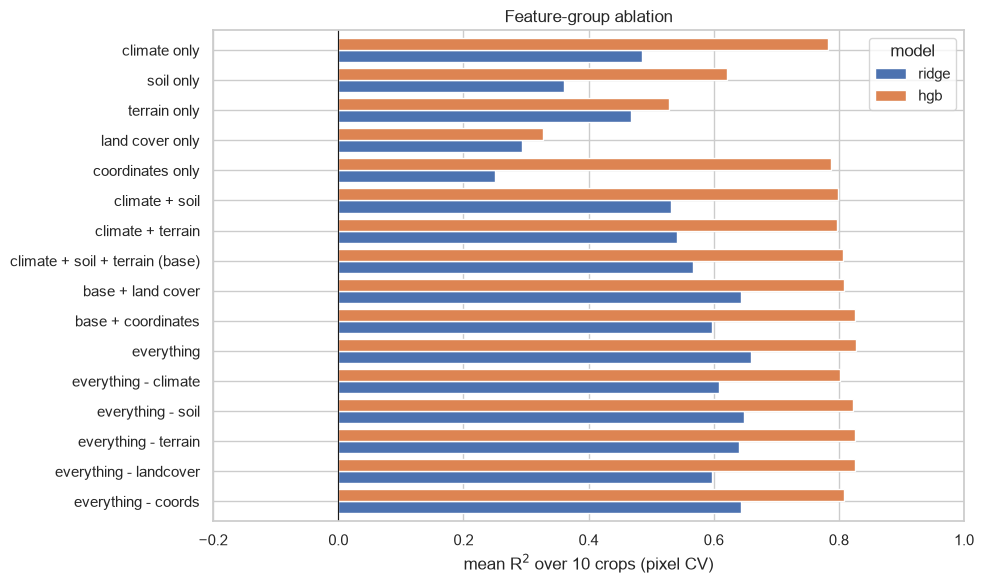

In [6]:
fig, ax = plt.subplots(figsize=(10, 6))
tbl[MODELS].iloc[::-1].plot.barh(ax=ax, width=0.8)
ax.set(xlabel="mean R$^2$ over 10 crops (pixel CV)", ylabel="", xlim=(-0.2, 1), title="Feature-group ablation")
ax.axvline(0, color="k", lw=0.8)
plt.tight_layout()
E.save_fig(fig, "m03_featuresets")
plt.show()

## 2. Leave-one-feature-out (HistGradientBoosting)
Drop in R$^2$ when a single variable is removed from the base set. Correlated variables (WorldClim vs CHIRPS rainfall, soil texture) substitute for each other, so small drops do not mean irrelevant.

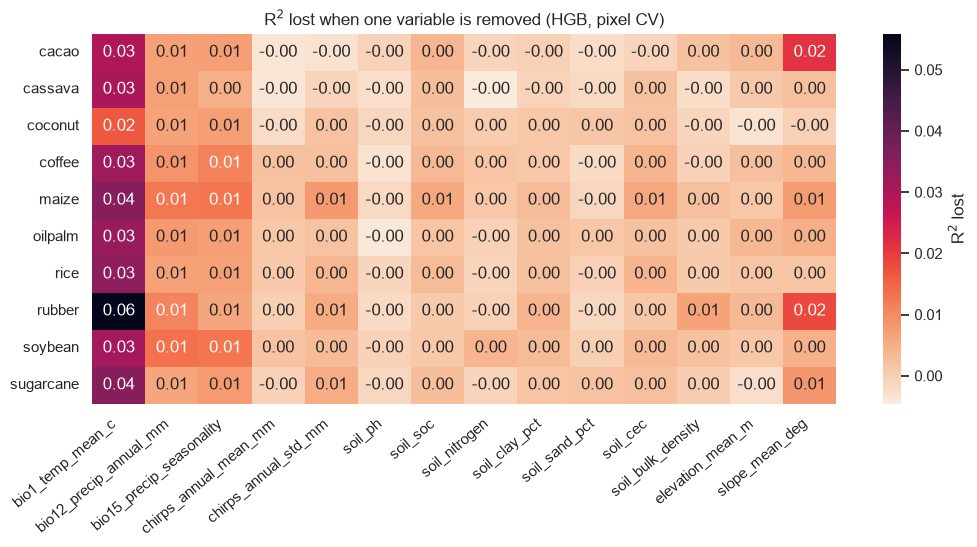

In [7]:
rows = []
full, _ = E.run_grid(df, targets, ["hgb"], ["pixel"], columns=base, n_repeats=2, verbose=False)
ref = full.groupby("target")["r2"].mean()
for f in base:
    cols = [c for c in base if c != f]
    r, _ = E.run_grid(df, targets, ["hgb"], ["pixel"], columns=cols, n_repeats=2, verbose=False)
    drop = ref - r.groupby("target")["r2"].mean()
    rows.append(drop.rename(f))
lofo = pd.DataFrame(rows).T[base]
E.save_table(lofo.round(4), "m03_leave_one_feature_out", index=True)
fig, ax = plt.subplots(figsize=(12, 4.8))
sns.heatmap(lofo, annot=True, fmt=".2f", cmap="rocket_r", ax=ax, cbar_kws={"label": "R$^2$ lost"})
ax.set(title="R$^2$ lost when one variable is removed (HGB, pixel CV)", xlabel="", ylabel="")
plt.xticks(rotation=40, ha="right")
E.save_fig(fig, "m03_leave_one_feature_out")
plt.show()

## 3. SHAP
XGBoost surrogate fitted on all cells (this explains what the model learned; it is not a performance estimate).

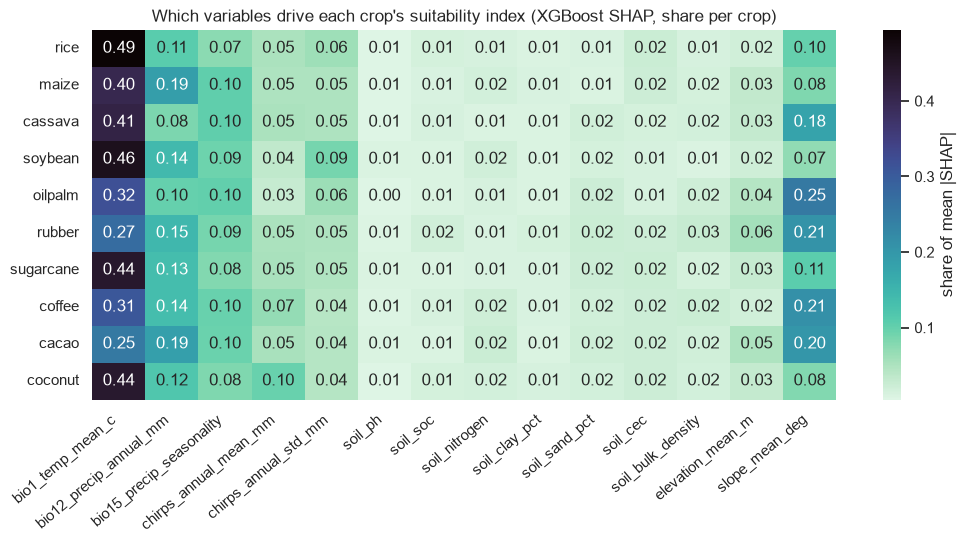

In [8]:
import shap
from xgboost import XGBRegressor

models, shap_vals = {}, {}
Xb = df[base].to_numpy(dtype=float)
for c in E.CROPS:
    m = XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=5, subsample=0.8, colsample_bytree=0.8,
                     min_child_weight=3, reg_lambda=2.0, tree_method="hist", n_jobs=E.N_JOBS, random_state=0)
    m.fit(Xb, targets[c])
    models[c] = m
    shap_vals[c] = shap.TreeExplainer(m).shap_values(Xb)

imp = pd.DataFrame({c: np.abs(shap_vals[c]).mean(axis=0) for c in E.CROPS}, index=base).T
imp_share = imp.div(imp.sum(axis=1), axis=0)
E.save_table(imp_share.round(4), "m03_shap_share", index=True)
fig, ax = plt.subplots(figsize=(12, 4.8))
sns.heatmap(imp_share, annot=True, fmt=".2f", cmap="mako_r", ax=ax, cbar_kws={"label": "share of mean |SHAP|"})
ax.set(title="Which variables drive each crop's suitability index (XGBoost SHAP, share per crop)", xlabel="", ylabel="")
plt.xticks(rotation=40, ha="right")
E.save_fig(fig, "m03_shap_share")
plt.show()

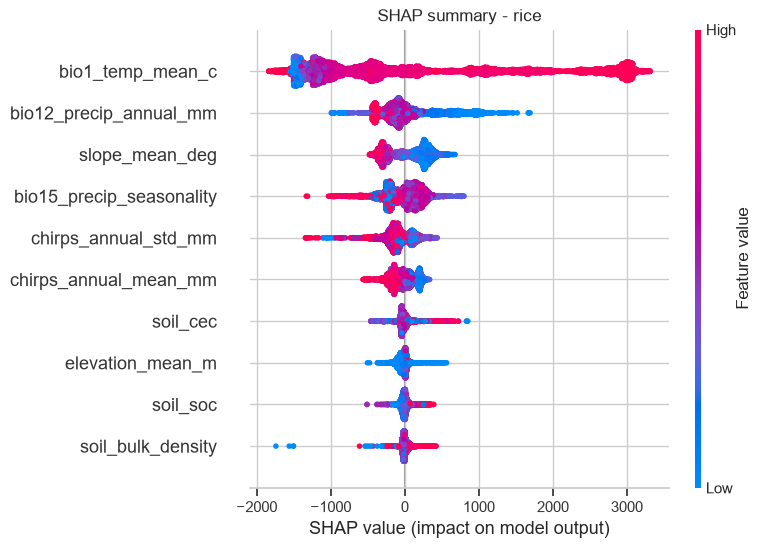

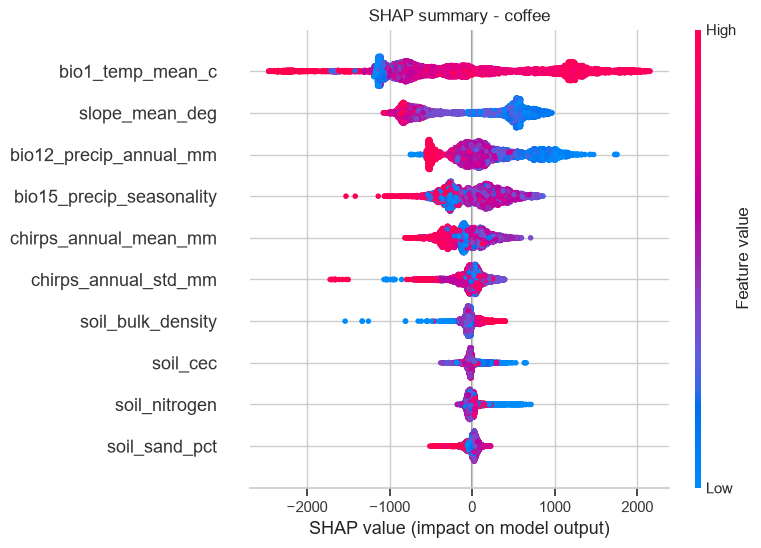

In [9]:
for c in ["rice", "coffee"]:
    plt.figure()
    shap.summary_plot(shap_vals[c], df[base], show=False, max_display=10)
    plt.title(f"SHAP summary - {c}")
    E.save_fig(plt.gcf(), f"m03_shap_beeswarm_{c}")
    plt.show()

## 4. Response curves
Partial dependence of the surrogate (average prediction while one variable is swept across its observed range).

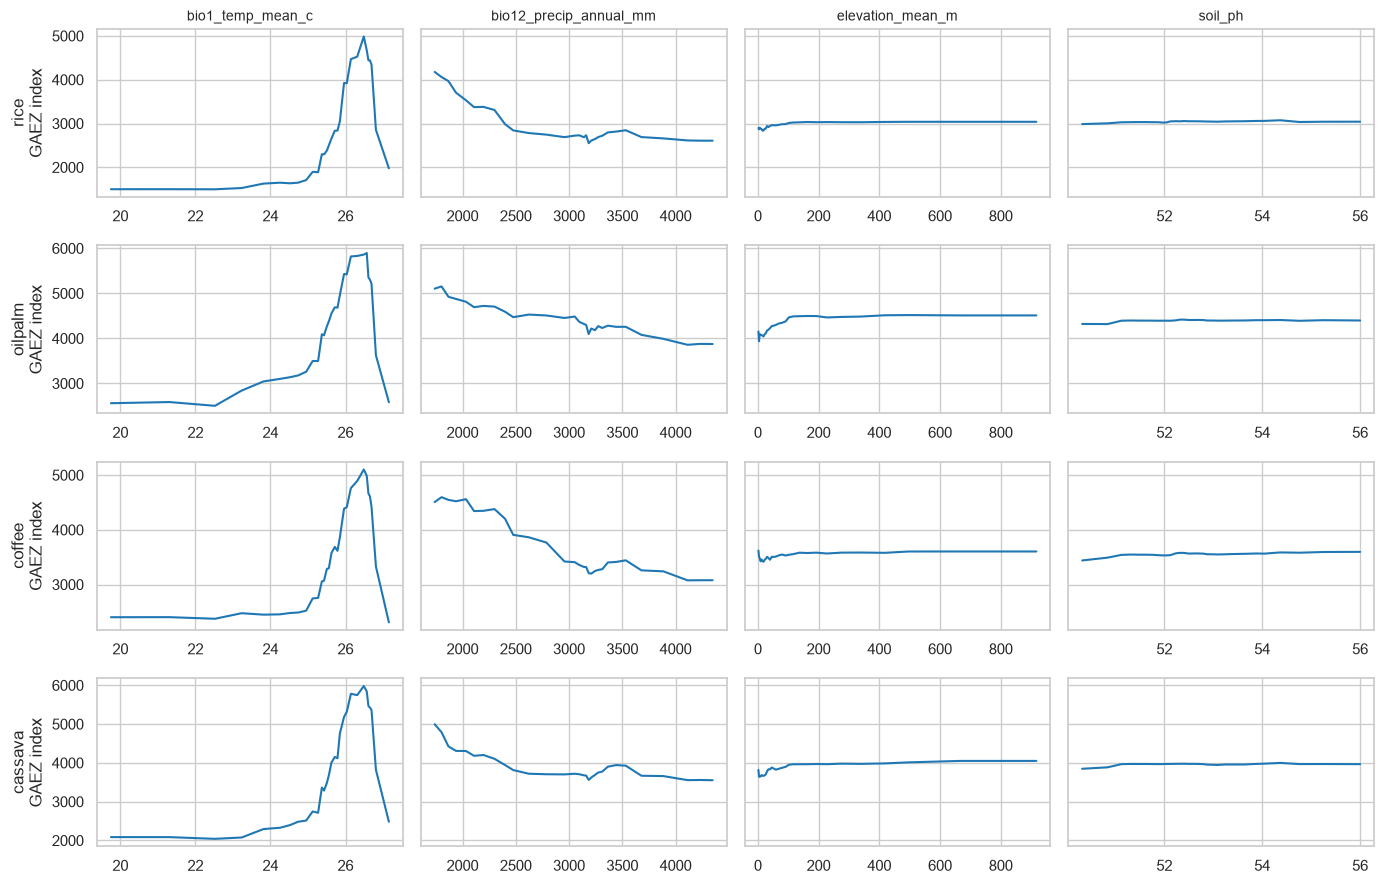

In [10]:
def partial_dependence(model, X, j, n_points=30):
    grid = np.quantile(X[:, j], np.linspace(0.02, 0.98, n_points))
    out = []
    for v in grid:
        Xv = X.copy(); Xv[:, j] = v
        out.append(model.predict(Xv).mean())
    return grid, np.array(out)

drivers = ["bio1_temp_mean_c", "bio12_precip_annual_mm", "elevation_mean_m", "soil_ph"]
show = ["rice", "oilpalm", "coffee", "cassava"]
Xi = df[base].fillna(df[base].median()).to_numpy(dtype=float)
fig, axes = plt.subplots(len(show), len(drivers), figsize=(14, 9), sharey="row")
for i, c in enumerate(show):
    for j, d in enumerate(drivers):
        g, p = partial_dependence(models[c], Xi, base.index(d))
        axes[i, j].plot(g, p, color="tab:blue")
        if i == 0: axes[i, j].set_title(d, fontsize=10)
        if j == 0: axes[i, j].set_ylabel(f"{c}\nGAEZ index")
plt.tight_layout()
E.save_fig(fig, "m03_partial_dependence")
plt.show()